# 2. Understand the model and rebuild the data

This notebook connects the model equation to pictures, reconstructs the Senate analysis grid from raw files, and finishes with the letter's exact three-by-three example.

By the end, you should be able to:

- Explain what changes when Euclidean distance is squared in the response equation.
- Follow the participation filters, random split, and training-outcome filter in their prescribed order.
- Verify the frozen outcomes, masks, and identifier ordering independently.
- Explain what the centered-matrix ranks establish, and what requires a separate proof.

Run the cells in order after installing the README dependencies. No fitting or downloading occurs. The first plot is illustrative; it does not show Senate estimates.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import os
import sys
import tempfile

working_directory = Path.cwd().resolve()
ROOT = next(
    (p for p in (working_directory, *working_directory.parents)
     if (p / "idealpoint").is_dir() and (p / "reference").is_dir()
     and (p / "data").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the replication repository.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"

# Keep the font cache temporary, without creating repository folders.
_plot_cache = tempfile.TemporaryDirectory(prefix="idealpoint-notebook-")
os.environ.setdefault("MPLCONFIGDIR", _plot_cache.name)
os.environ["MPLBACKEND"] = "Agg"

import numpy as np
import pandas as pd
from IPython.display import Image, display
from idealpoint.figures import configure, draw_exact

configure()
import matplotlib.pyplot as plt

def show_figure(figure, width=900):
    # Embedding the PNG works even when Matplotlib uses the Agg backend.
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=180, bbox_inches="tight")
        display(Image(data=buffer.getvalue(), format="png", width=width))
    plt.close(figure)

print("Repository found. Figures will appear below their code cells.")

Repository found. Figures will appear below their code cells.


## 1. Start with distance, log odds, and probability

The legislator and roll call have positions $z_i$ and $w_j$. Their Euclidean distance is $r=\lVert z_i-w_j\rVert_2$. The response model applies a penalty to that distance:

$$\eta_{ij}=a_i+b_j-\gamma r^q,\qquad
p_{ij}=\frac{1}{1+\exp(-\eta_{ij})}.$$

Here $\eta_{ij}$ is the log odds of Yea and $p_{ij}$ is its probability. The exponent is $q=1$ for unsquared distance and $q=2$ for squared distance.

The next plot holds the combined intercept $a_i+b_j=2$ and coefficient $\gamma=1$ fixed. Only separation $r$ changes. These chosen constants illustrate the equation; they do not describe a fitted senator or roll call.

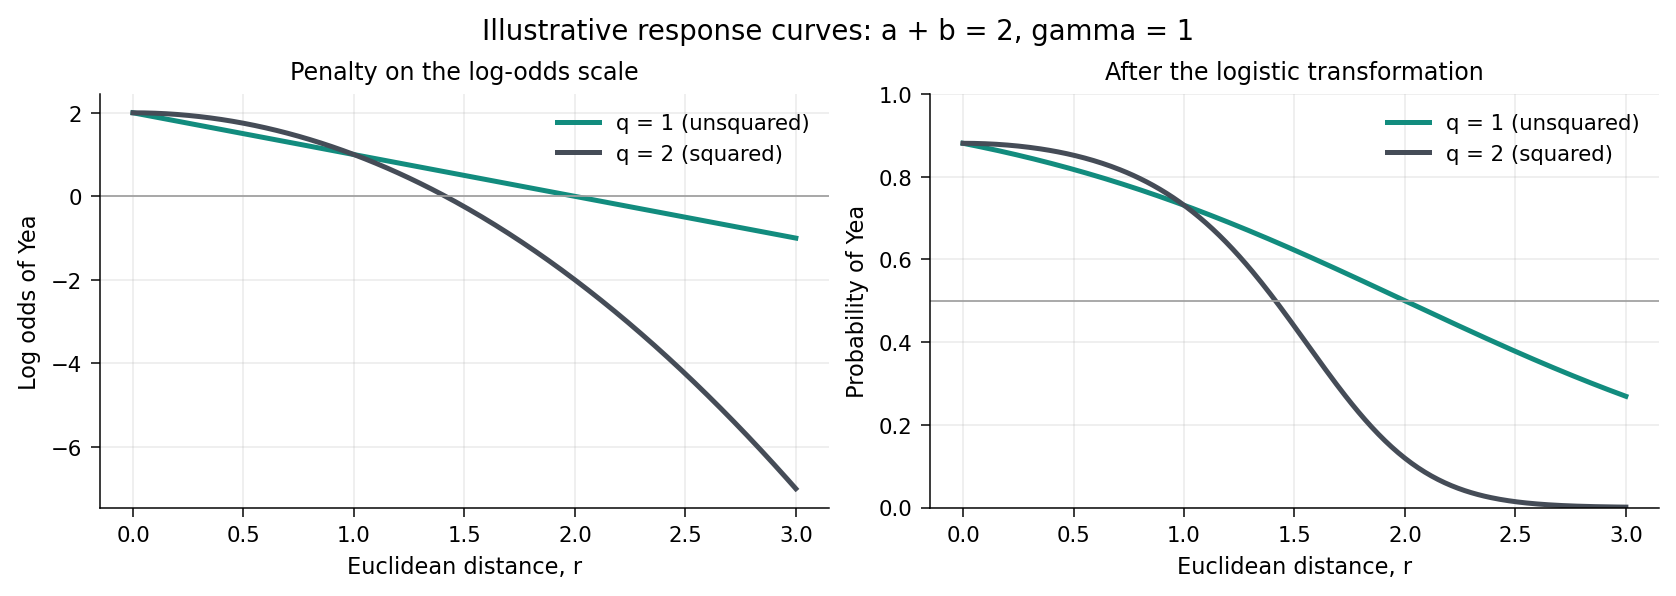

In [2]:
distance = np.linspace(0, 3, 301)
combined_intercept, gamma = 2.0, 1.0
colors = {1: "#128c7e", 2: "#454c57"}
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.2), layout="constrained")
for q in (1, 2):
    eta = combined_intercept - gamma * distance**q
    probability = np.exp(-np.logaddexp(0, -eta))
    label = f"q = {q} ({'unsquared' if q == 1 else 'squared'})"
    axes[0].plot(distance, eta, color=colors[q], label=label, linewidth=2)
    axes[1].plot(distance, probability, color=colors[q], label=label, linewidth=2)
for ax in axes:
    ax.set_xlabel("Euclidean distance, r")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
axes[0].set(title="Penalty on the log-odds scale", ylabel="Log odds of Yea")
axes[0].axhline(0, color="#a0a0a0", linewidth=0.7)
axes[1].set(title="After the logistic transformation", ylabel="Probability of Yea", ylim=(0, 1))
axes[1].axhline(0.5, color="#a0a0a0", linewidth=0.7)
fig.suptitle("Illustrative response curves: a + b = 2, gamma = 1", fontsize=11)
show_figure(fig)

Read the left panel first. Each additional unit reduces the unsquared model's log odds by one. Under squared distance, moving from $r$ to $r+1$ reduces log odds by $2r+1$.

The right panel applies the same logistic function to both curves. A constant change in log odds does not imply a constant change in probability. The curve flattens near zero and one.

Both models use Euclidean distance. Squaring it changes the response penalty, not the coordinate metric. Their crossing at $r=1$ follows from $r=r^2$ in these illustrative units; it is not a political threshold.

## 2. Check the Senate source snapshot

The Senate comparison uses two coordinates, $\gamma=1$, independent $N(0,3^2)$ intercepts, and independent $N(0,s^2)$ coordinate components for $s=0.5,1,2$. The estimates are approximate joint MAP fits. Common parameter priors do not imply common priors on vote probabilities.

Before estimation, we need a reproducible response grid. The bundled Voteview snapshot contains member, roll-call, and vote files. The next cell compares their SHA-256 digests with the recorded design.

NOMINATE scores and party membership do not enter the fitting objective. Party labels are used after estimation for display orientation and descriptive comparisons.

In [3]:
design = json.loads((DATA / "fit_comparison_design.json").read_text())
source_checks = []
for filename, source in design["sources"].items():
    digest = hashlib.sha256((DATA / filename).read_bytes()).hexdigest()
    source_checks.append({
        "Source file": filename,
        "Matches recorded SHA-256": digest == source["sha256"],
    })
source_table = pd.DataFrame(source_checks)
display(source_table)
assert source_table["Matches recorded SHA-256"].all(), "A bundled source file has changed."
print("Source URLs and the split rule are recorded in the design file.")

,Source file,Matches recorded SHA-256
0,S114_votes.csv,True
1,S114_members.csv,True
2,S114_rollcalls.csv,True


Source URLs and the split rule are recorded in the design file.


## 3. Build a grid of observed votes

Rows represent senators and columns represent roll calls. Cast code 1 becomes Yea, coded as one. Cast code 6 becomes Nay, coded as zero. Other cast codes remain missing.

We use the Senate member roster as well as the vote file's chamber field. This excludes presidential records that can appear among Senate votes. Identifiers are sorted before constructing the matrix.

In [4]:
members_raw = pd.read_csv(DATA / "S114_members.csv")
rollcalls_raw = pd.read_csv(DATA / "S114_rollcalls.csv")
votes_raw = pd.read_csv(DATA / "S114_votes.csv")

senate_members = members_raw.loc[members_raw["chamber"].eq("Senate")].drop_duplicates("icpsr")
member_ids = np.sort(senate_members["icpsr"].to_numpy(dtype=int))
roll_ids = np.sort(rollcalls_raw.loc[
    rollcalls_raw["chamber"].eq("Senate"), "rollnumber"
].unique().astype(int))
initial_members, initial_rollcalls = len(member_ids), len(roll_ids)

eligible = votes_raw.loc[
    votes_raw["chamber"].eq("Senate")
    & votes_raw["cast_code"].isin([1, 6])
    & votes_raw["icpsr"].isin(member_ids)
].copy()
assert not eligible.duplicated(["icpsr", "rollnumber"]).any(), "Duplicate observed votes."
assert eligible["rollnumber"].isin(roll_ids).all(), "A vote has no matching Senate roll call."

member_index = {identifier: i for i, identifier in enumerate(member_ids)}
roll_index = {identifier: j for j, identifier in enumerate(roll_ids)}
row_index = eligible["icpsr"].map(member_index).to_numpy(dtype=int)
column_index = eligible["rollnumber"].map(roll_index).to_numpy(dtype=int)
outcomes = np.full((len(member_ids), len(roll_ids)), np.nan)
outcomes[row_index, column_index] = eligible["cast_code"].eq(1).to_numpy(dtype=float)
print(f"Original grid: {initial_members} senators × {initial_rollcalls} roll calls.")

Original grid: 100 senators × 502 roll calls.


The initial grid includes every Senate roll call in the snapshot. Missing entries mean no observed Yea/Nay response, not opposition.

The first filter retains senators with Yea/Nay responses on at least 80% of the original roll calls. This filter uses participation, not whether a senator voted Yea or Nay. Retained rows keep their sorted identifier order.

In [5]:
retain_member = np.isfinite(outcomes).sum(axis=1) >= np.ceil(0.8 * len(roll_ids))
outcomes = outcomes[retain_member]
member_ids = member_ids[retain_member]
assert np.all(np.diff(member_ids) > 0)
print(f"Retained {len(member_ids)} of {initial_members} senators before drawing the split.")

Retained 96 of 100 senators before drawing the split.


## 4. Draw the split before filtering roll-call outcomes

Each observed entry is assigned to training or evaluation by an independent uniform draw. The recorded seed fixes those draws. Approximately 20% of observed entries are held out.

Draws are made on the entire retained-senator grid before filtering roll calls. Reordering rows, changing this sequence, or drawing only on observed entries would produce a different split with the same seed.

In [6]:
observed = np.isfinite(outcomes)
rng = np.random.default_rng(design["split"]["seed"])
draws = rng.random(outcomes.shape)
test_fraction = design["split"]["test_probability"]
train = observed & (draws >= test_fraction)
test = observed & (draws < test_fraction)

assert not np.any(train & test)
assert np.array_equal(train | test, observed)
print(f"Fixed seed: {design['split']['seed']}; held-out probability: {test_fraction:.0%}.")

Fixed seed: 20261023; held-out probability: 20%.


Now retain roll calls with sufficient participation and training information. Each retained column must have:

- Yea/Nay responses from at least 80% of retained senators.
- At least 50 training votes.
- A training Yea share between 0.1 and 0.9, inclusive.

The last rule excludes extremely unbalanced training columns. Held-out Yea/Nay values do not determine this balance filter. Participation checks still use whether a vote was observed.

In [7]:
training_count = train.sum(axis=0)
training_yeas = np.where(train, outcomes, 0).sum(axis=0)
training_share = np.divide(
    training_yeas, training_count,
    out=np.zeros_like(training_yeas), where=training_count > 0,
)
retain_roll = (
    (observed.sum(axis=0) >= np.ceil(0.8 * len(member_ids)))
    & (training_count >= 50)
    & (training_share >= 0.1)
    & (training_share <= 0.9)
)
outcomes = outcomes[:, retain_roll]
train = train[:, retain_roll]
test = test[:, retain_roll]
roll_ids = roll_ids[retain_roll]

# Missing entries are stored as zero only for array storage. The masks exclude
# them from both fitting and scoring, so they are never treated as Nay votes.
rebuilt = {
    "y": np.nan_to_num(outcomes),
    "train": train,
    "test": test,
    "member_ids": member_ids,
    "roll_ids": roll_ids,
}
assert not np.any(train & test)
assert np.array_equal(train | test, np.isfinite(outcomes))

assert np.all(np.diff(roll_ids) > 0)
print(f"Retained {len(roll_ids)} of {initial_rollcalls} roll calls.")

Retained 373 of 502 roll calls.


## 5. Verify the reconstructed analysis data

A matching sample size is not enough: two splits can contain the same number of votes but assign different entries to evaluation.

The next cell compares every outcome, mask entry, and identifier with the frozen arrays. It also checks the reported counts. These comparisons are independent of fitted positions.

In [8]:
array_checks = []
with np.load(DATA / "fit_comparison_split.npz", allow_pickle=False) as saved:
    for name, rebuilt_array in rebuilt.items():
        array_checks.append({
            "Array": name,
            "Shape": str(rebuilt_array.shape),
            "Exact match": np.array_equal(rebuilt_array, saved[name]),
        })
array_table = pd.DataFrame(array_checks)
display(array_table)
assert array_table["Exact match"].all(), "The rebuilt split differs from the stored split."

rebuilt_counts = {
    "n_members": len(member_ids),
    "n_rollcalls": len(roll_ids),
    "n_observed": int((train | test).sum()),
    "n_train": int(train.sum()),
    "n_test": int(test.sum()),
    "n_missing": int((~(train | test)).sum()),
}
count_table = pd.DataFrame({
    "Rebuilt": rebuilt_counts,
    "Recorded": {key: design[key] for key in rebuilt_counts},
})
display(count_table)
assert count_table["Rebuilt"].equals(count_table["Recorded"])

print("All five arrays and recorded sample counts match exactly.")

,Array,Shape,Exact match
0,y,"(96, 373)",True
1,train,"(96, 373)",True
2,test,"(96, 373)",True
3,member_ids,"(96,)",True
4,roll_ids,"(373,)",True


,Rebuilt,Recorded
n_members,96,96
n_rollcalls,373,373
n_observed,35182,35182
n_train,28164,28164
n_test,7018,7018
n_missing,626,626


All five arrays and recorded sample counts match exactly.


## 6. See what the masks represent

The following image shows the final grid. Each cell records its role: training, held out, or missing. It does not show whether the response was Yea or Nay.

Rows remain in sorted senator-identifier order, and columns remain in sorted roll-number order. Neither axis is sorted by party or estimated position. Tick labels show a few identifiers to make the ordering visible.

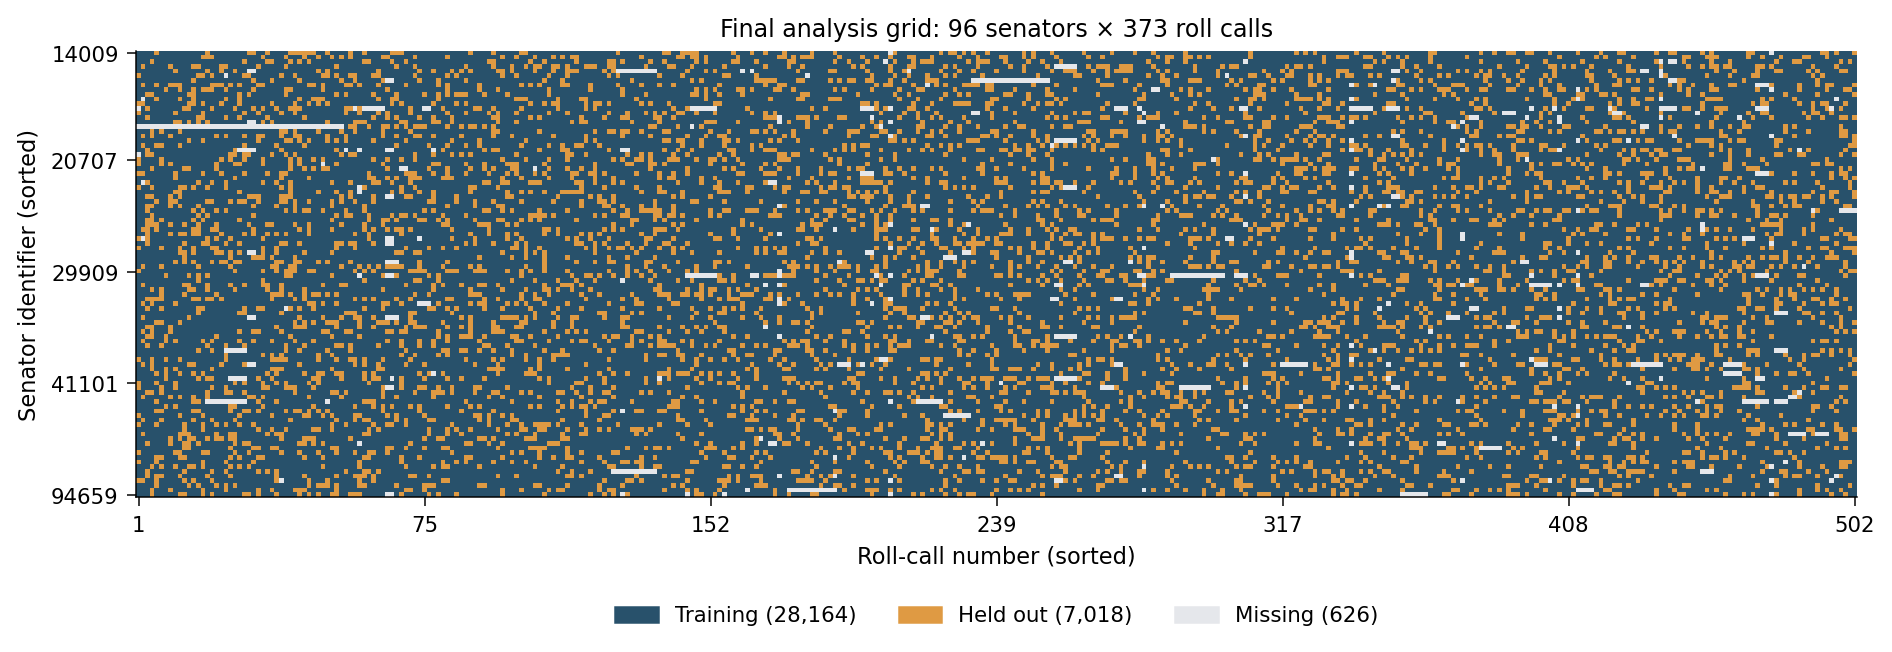

In [9]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

# 0 = missing, 1 = training, 2 = held out.
role = np.zeros(train.shape, dtype=np.uint8)
role[train], role[test] = 1, 2
role_colors = ["#e5e7eb", "#28516b", "#df9a43"]
cmap = ListedColormap(role_colors)
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap.N)
fig, ax = plt.subplots(figsize=(10.4, 3.5), layout="constrained")
ax.imshow(role, cmap=cmap, norm=norm, aspect="auto", interpolation="nearest")
xticks = np.linspace(0, len(roll_ids) - 1, 7, dtype=int)
yticks = np.linspace(0, len(member_ids) - 1, 5, dtype=int)
ax.set_xticks(xticks, labels=roll_ids[xticks])
ax.set_yticks(yticks, labels=member_ids[yticks])
ax.set(
    title=f"Final analysis grid: {len(member_ids)} senators × {len(roll_ids)} roll calls",
    xlabel="Roll-call number (sorted)", ylabel="Senator identifier (sorted)",
)
ax.legend(
    handles=[
        Patch(color=role_colors[1], label=f"Training ({train.sum():,})"),
        Patch(color=role_colors[2], label=f"Held out ({test.sum():,})"),
        Patch(color=role_colors[0], label=f"Missing ({(~(train | test)).sum():,})"),
    ],
    loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False,
)
show_figure(fig, width=1000)

Most cells belong to training, with held-out cells distributed across the same senators and roll calls. Gray cells are excluded from both fitting and scoring.

This design evaluates additional votes from senators and roll calls represented in training. It does not evaluate entirely new senators or roll calls. The image illustrates the mask; the exact array comparisons establish that it is the intended split.

## 7. Work through the exact one-dimensional example

We now leave the Senate data and use three actors and three items at $(-1,0,1)$. Set all intercepts to zero and $\gamma=1$. Then $\eta_{ij}=-|t_i-t_j|^q$.

Double centering subtracts each row mean and column mean, then adds the grand mean:

$$C_{ij}=\eta_{ij}-\bar\eta_{i\cdot}-\bar\eta_{\cdot j}+\bar\eta_{\cdot\cdot}.$$

This removes additive actor and item effects. Rational arithmetic gives exact matrix entries rather than rounded floating-point approximations.

In [10]:
from fractions import Fraction
from idealpoint.checks import exact_checks

positions = [-1, 0, 1]
centered_by_q = {}
for q in (1, 2):
    eta = [[Fraction(-abs(x - w)**q) for w in positions] for x in positions]
    row_means = [sum(row) / 3 for row in eta]
    column_means = [sum(eta[i][j] for i in range(3)) / 3 for j in range(3)]
    grand_mean = sum(row_means) / 3
    centered_by_q[q] = [
        [eta[i][j] - row_means[i] - column_means[j] + grand_mean for j in range(3)]
        for i in range(3)
    ]
exact_report = exact_checks()
assert exact_report["passed"]
for q in (1, 2):
    assert [[str(v) for v in row] for row in centered_by_q[q]] == (
        exact_report["centered_logit_matrices"][q - 1]
    )
display(pd.DataFrame({
    "Distance exponent": [1, 2],
    "Centered-matrix rank": exact_report["ranks"],
    "Eigenvalues": [", ".join(values) for values in exact_report["eigenvalues"]],
}))

,Distance exponent,Centered-matrix rank,Eigenvalues
0,1,2,"0, 2/3, 2"
1,2,1,"0, 0, 4"


The figure below displays those same centered log odds. Read the values printed in the cells; color provides another way to see their signs and magnitudes.

These are not distance matrices. Centered log odds may be negative, and their diagonal need not be zero. The left matrix has rank two; the right matrix has rank one.

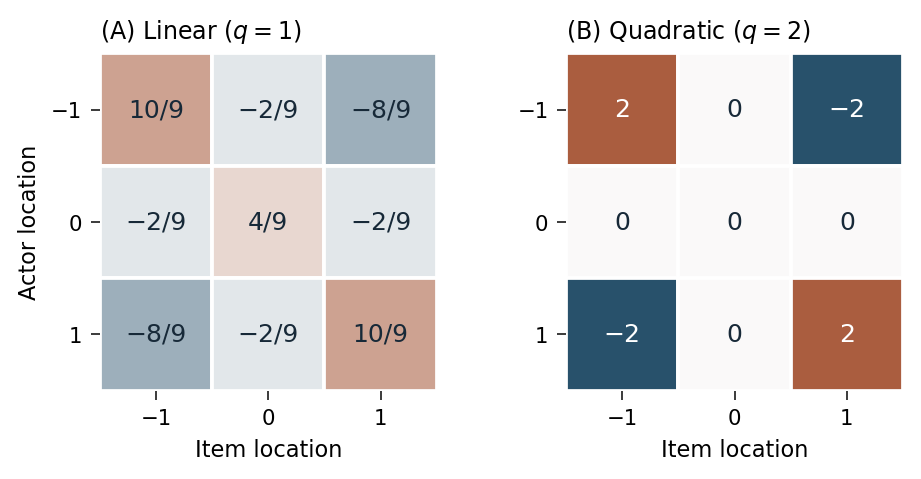

Exact ranks: unsquared distance = 2; squared distance = 1.


In [11]:
exact_figure = draw_exact(exact_report)
show_figure(exact_figure, width=850)
print("Exact ranks: unsquared distance = 2; squared distance = 1.")

## 8. Separate the rank result from the second exclusion

With squared distance and unrestricted intercepts, expanding the square leaves a bilinear interaction after centering. In $K$ dimensions, the complete centered log-odds matrix therefore has rank at most $K$.

The rank-two matrix on the left cannot have any one-dimensional squared-distance representation, even after changing positions and intercepts. The right matrix's rank alone does not settle whether unsquared distance could reproduce it.

That second question uses rectangular contrasts, such as $\eta_{11}+\eta_{22}-\eta_{12}-\eta_{21}$. Row and column effects cancel in each contrast, so centering does not change it. The next cell extracts the two contrasts used in the contradiction.

In [12]:
contrasts = exact_report["quadratic_ordered_rectangles"]
display(pd.DataFrame({
    "Actor pair": ["1 and 2", "2 and 3"],
    "Item pair": ["2 and 3", "1 and 2"],
    "Quadratic-target contrast": [contrasts["0,1,1,2"], contrasts["1,2,0,1"]],
}))
assert Fraction(contrasts["0,1,1,2"]) > 0
assert Fraction(contrasts["1,2,0,1"]) > 0
print("Both contrasts are strictly positive.")

,Actor pair,Item pair,Quadratic-target contrast
0,1 and 2,2 and 3,2
1,2 and 3,1 and 2,2


Both contrasts are strictly positive.


For unsquared distance on a line, these contrasts depend on overlap between actor and item intervals. After establishing their common ordering, matching both positive contrasts would require the middle actor to lie on both sides of the middle item. The appendix gives that proof.

Thus neither one-dimensional family contains the other. The finite arithmetic here checks the example; it does not replace the general argument. The result does not establish noncontainment in every dimension or rank predictive performance.

### What to carry forward

- The distance exponent changes the response equation while the coordinates remain Euclidean.
- The Senate illustration uses a reproducible split with a training-only outcome-balance filter.
- Exact ranks establish one direction of the one-dimensional exclusion; interval overlap establishes the other.
- These mathematical statements and the Senate comparison answer different questions.

Return to *1_reproduce_manuscript.ipynb* for the archived results, or continue to *3_refit_senate.ipynb* to generate and check new estimates.